# Customer EDA #

## Importing Libraries ##

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

## Load Data ##

In [2]:
df_customer_order = pd.read_parquet(
    "../data/customer_orders_2024-01_2026-08.parquet"
)
df_customer_order.head()

,user_id,order_id,order_datetime,pick_up_date,timeslot,pickup_point,sku,ean_code,product_name,quantity,old_price,new_price,date_type,expiry_date,shop_branch,regular_client
0,0DKWGcJ8itd0AxqSldV9lI6p74l2,d22551a6-1c57-47f9-b003-4531cbf5bef6,2025-01-18 08:34:52,2025-01-18,17:00 - 20:00,b3233bd3323f1aee,08ef34c7-9014-423e-b203-f58ce0d289a9,8714100768990,Knorr | Soupe | Tomates avec boulettes,2,2.95,1.2,DDM,2024-12-09 11:00:00+00:00,8fbf3758005e6c86,True
1,0DKWGcJ8itd0AxqSldV9lI6p74l2,d22551a6-1c57-47f9-b003-4531cbf5bef6,2025-01-18 08:34:52,2025-01-18,17:00 - 20:00,b3233bd3323f1aee,3b266c7d-108a-4cc8-af1c-3d07e1ad64ca,5414972130378,aiki yakisoba cup curry 118gr,1,2.55,1.8,DDM,2025-10-10 10:00:00+00:00,8fbf3758005e6c86,True
2,0DKWGcJ8itd0AxqSldV9lI6p74l2,d22551a6-1c57-47f9-b003-4531cbf5bef6,2025-01-18 08:34:52,2025-01-18,17:00 - 20:00,b3233bd3323f1aee,80bad095-4ff2-4e98-a84b-0411f5c5a82a,5400119591058,Assortiment de poissons préparés,2,7.49,3.7,DLC,2025-01-18 11:00:00+00:00,a5a5c77a53f3bd84,True
3,0DKWGcJ8itd0AxqSldV9lI6p74l2,d22551a6-1c57-47f9-b003-4531cbf5bef6,2025-01-18 08:34:52,2025-01-18,17:00 - 20:00,b3233bd3323f1aee,TLgvCPnt9yLfDvIbfy3N,5400119609517,Tomates Cocktail - 300g,1,2.99,1.8,DLC,2025-01-31 11:00:00+00:00,681c112345a19fa2,True
4,0DKWGcJ8itd0AxqSldV9lI6p74l2,d22551a6-1c57-47f9-b003-4531cbf5bef6,2025-01-18 08:34:52,2025-01-18,17:00 - 20:00,b3233bd3323f1aee,vTRH2U87UGg45d3Wru2v,5400119575829,Tomates cerise | rouge 1kg,1,6.49,3.9,DLC,2025-01-31 11:00:00+00:00,681c112345a19fa2,True


In [3]:
df_customer_order.shape

(967415, 16)

In [4]:
df_customer_order.columns.tolist()

['user_id',
 'order_id',
 'order_datetime',
 'pick_up_date',
 'timeslot',
 'pickup_point',
 'sku',
 'ean_code',
 'product_name',
 'quantity',
 'old_price',
 'new_price',
 'date_type',
 'expiry_date',
 'shop_branch',
 'regular_client']

## Check for Missing Values and Duplicates ##

In [5]:
df_customer_order.info()

<class 'pandas.DataFrame'>
RangeIndex: 967415 entries, 0 to 967414
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   user_id         967415 non-null  str                
 1   order_id        967415 non-null  str                
 2   order_datetime  967415 non-null  datetime64[us]     
 3   pick_up_date    967415 non-null  object             
 4   timeslot        967415 non-null  str                
 5   pickup_point    967415 non-null  str                
 6   sku             967415 non-null  str                
 7   ean_code        967415 non-null  str                
 8   product_name    967415 non-null  str                
 9   quantity        967415 non-null  int64              
 10  old_price       967415 non-null  float64            
 11  new_price       967415 non-null  float64            
 12  date_type       967415 non-null  str                
 13  expiry_date     967415 no

In [6]:
df_customer_order.duplicated().sum()

np.int64(0)

In [7]:
df_customer_order.isnull().sum()

user_id           0
order_id          0
order_datetime    0
pick_up_date      0
timeslot          0
pickup_point      0
sku               0
ean_code          0
product_name      0
quantity          0
old_price         0
new_price         0
date_type         0
expiry_date       0
shop_branch       0
regular_client    0
dtype: int64

In [8]:
df_customer_order.nunique()

user_id             1000
order_id          141153
order_datetime    140476
pick_up_date         544
timeslot              13
pickup_point          24
sku               373117
ean_code           37731
product_name       42895
quantity              55
old_price           2253
new_price            363
date_type              2
expiry_date         2038
shop_branch          226
regular_client         2
dtype: int64

In [9]:
df_customer_order.describe()

,order_datetime,quantity,old_price,new_price
count,967415,967415.000000,967415.000000,967415.000000
mean,2025-10-22 15:27:31.270878,1.401664,4.021340,2.253330
min,2024-12-02 11:47:47,1.000000,0.000000,0.000000
25%,2025-05-23 13:13:19,1.000000,2.120000,1.200000
50%,2025-10-23 11:24:29,1.000000,3.200000,1.800000
75%,2026-03-24 10:47:00,1.000000,4.980000,2.700000
max,2026-08-31 22:55:28,171.000000,204.000000,102.000000
std,NaN,1.195861,3.490239,1.942082


### order_datetime ###
The data runs from 2 Dec 2024 to 31 Aug 2026, about 21 months.
The mean (22 Oct 2025) and median (23 Oct 2025) are almost identical, and the quartiles are spaced about 5 months apart. That means orders are spread fairly evenly over time, with no big gaps or spikes in volume.

### quantity ###
The median and the 25th and 75th percentiles are all 1, so at least 75% of orders are for a single unit.
The mean is 1.40, above the median, which signals right skew: a small number of orders pull the average up.
The max is 171, far from the typical value of 1. That could be a genuine bulk order or a data error, so it’s worth inspecting.

### old_price ###
Typical (median) price is 3.20, the mean is 4.02, and the middle 50% falls between 2.12 and 4.98.
It’s also right-skewed, with a max of 204, so a few expensive items exist.
The minimum is 0, which could be free items or missing prices coded as 0.

### new_price ###
It looks like a discounted version of old_price. Every statistic is roughly 45% lower: the median is 1.80 vs 3.20, the mean 2.25 vs 4.02, and the max 102 vs 204 (exactly half).
It also has a minimum of 0.

In [11]:
orders_per_customer = (
    df_customer_order.groupby("user_id")["order_id"]
    .nunique()
)

orders_per_customer.describe()

count    1000.000000
mean      141.153000
std       124.743555
min         1.000000
25%        77.000000
50%       119.500000
75%       181.250000
max      1053.000000
Name: order_id, dtype: float64

Customer purchasing frequency varies considerably. Some customers placed only one order, while the most active customer placed 1,053 orders.

The average exceeds the median, suggesting a right-skewed distribution with some particularly frequent buyers.

In [13]:
products_per_order = (
    df_customer_order.groupby("order_id")
    .size()
)

products_per_order.describe()

count    141153.000000
mean          6.853662
std           5.745380
min           1.000000
25%           3.000000
50%           5.000000
75%           9.000000
max          76.000000
dtype: float64

An average order contains approximately 6.85 product rows.

These are just basket lines, not necessarily individual units. A customer purchasing three units of the same product may still have only one basket line.

In [15]:
# Number of distinct customers by regular_client status
customer_status = (
    df_customer_order.groupby("regular_client")["user_id"]
    .nunique()
)

customer_status

regular_client
False    200
True     800
Name: user_id, dtype: int64

zero customers have both regular_client statuses.

Therefore, each customer has a consistent regular/non-regular classification within this dataset.

In [18]:
status_changes = (
    df_customer_order.groupby("user_id")["regular_client"]
    .nunique()
)

(status_changes > 1).sum()

np.int64(0)

In [21]:
df_customer_order["order_datetime"].min()

Timestamp('2024-12-02 11:47:47')

In [22]:
df_customer_order["order_datetime"].max()

Timestamp('2026-08-31 22:55:28')

In [26]:
(df_customer_order["order_datetime"].max() - df_customer_order["order_datetime"].min()).days

637

In [28]:
monthly_orders = (
    df_customer_order.assign(
        order_month=df_customer_order["order_datetime"].dt.to_period("M")
    )
    .groupby("order_month")["order_id"]
    .nunique()
)
monthly_orders

order_month
2024-12    4925
2025-01    6258
2025-02    6114
2025-03    6959
2025-04    7499
2025-05    7712
2025-06    7237
2025-07    6777
2025-08    6719
2025-09    7609
2025-10    8115
2025-11    7437
2025-12    7577
2026-01    7380
2026-02    6287
2026-03    6754
2026-04    6370
2026-05    6473
2026-06    6347
2026-07    5268
2026-08    5336
Freq: M, Name: order_id, dtype: int64

## Obervations ##
- Orders generally increased during the first half of 2025.
- October 2025 recorded the highest monthly order count.
- Order volume fluctuated through late 2025 and early 2026.
- July and August 2026 showed relatively low activity.
For example, orders decreased from 7,380 in January 2026 to 5,336 in August 2026, a decline of approximately 27.7%.

A decline in total orders could reflect several possibilities, including customers ordering less frequently, fewer active customers, seasonal changes or changes in product availability.

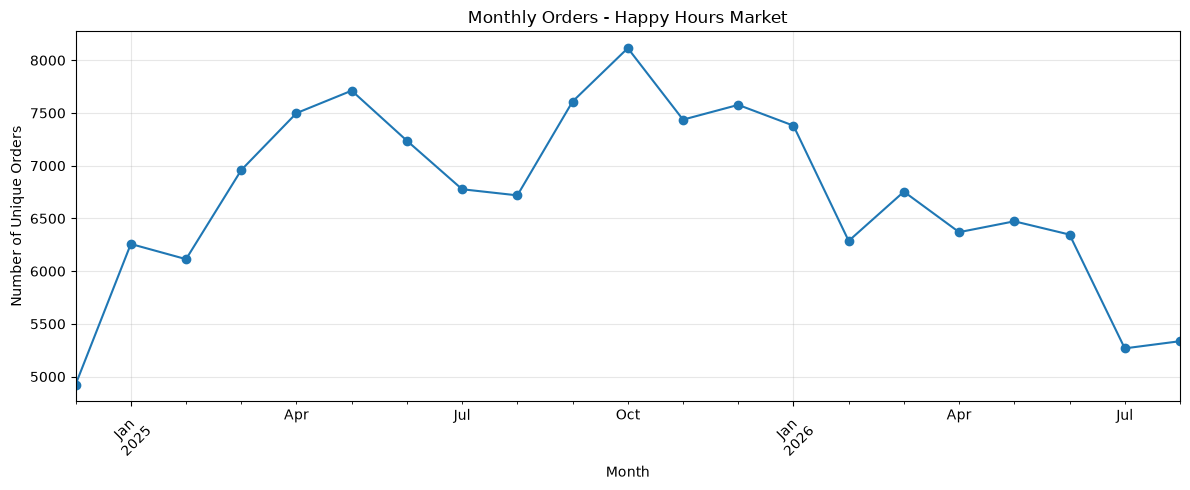

In [30]:
plt.figure(figsize=(12, 5))

monthly_orders.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Orders - Happy Hours Market")
plt.xlabel("Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
df_customer_order["quantity"].describe()

count    967415.000000
mean          1.401664
std           1.195861
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         171.000000
Name: quantity, dtype: float64

Most basket lines contain one unit. There are no zero or negative quantities.
171 bulk purchase?

In [32]:
(df_customer_order["quantity"] == 0).sum()

np.int64(0)

In [33]:
(df_customer_order["quantity"] < 0).sum()

np.int64(0)

In [34]:
df_customer_order["old_price"].describe()

count    967415.000000
mean          4.021340
std           3.490239
min           0.000000
25%           2.120000
50%           3.200000
75%           4.980000
max         204.000000
Name: old_price, dtype: float64

In [35]:
df_customer_order["new_price"].describe()

count    967415.000000
mean          2.253330
std           1.942082
min           0.000000
25%           1.200000
50%           1.800000
75%           2.700000
max         102.000000
Name: new_price, dtype: float64

In [38]:
(df_customer_order["new_price"] == 0).sum()

np.int64(50)

In [39]:
(df_customer_order["new_price"] < 0).sum()

np.int64(0)

50 rows with a zero selling price. = free products, promotions or data errors?
0 rows with negative selling prices.

In [41]:
# New price greater than old price
(df_customer_order["new_price"] > df_customer_order["old_price"]).sum()

np.int64(113)

In [42]:
# New price equal to old price
(df_customer_order["new_price"] == df_customer_order["old_price"]).sum()

np.int64(146)

In [43]:
# New price lower than old price
(df_customer_order["new_price"] < df_customer_order["old_price"]).sum()

np.int64(967156)

Selling price equals original price : 146
Selling price exceeds original price : 113

The 113 rows where the selling price exceeds the original price are potential anomalies, but they account for only approximately 0.012% of the dataset.

In [44]:
df_customer_order.nlargest(10, "quantity")[
    [
        "order_id",
        "product_name",
        "quantity",
        "old_price",
        "new_price"
    ]
]

,order_id,product_name,quantity,old_price,new_price
469092,2fa0de47-6ad4-48ed-be20-dd012181c9e0,Fruit de la passion vrac 1x,171,0.50,0.3
668749,b25f2533-9846-4710-90a2-bd51fc6b320c,Pils bierre - Premium quality Derby,120,0.40,0.3
469072,85b119d5-7c04-4419-a552-e5f1e0c152c7,Fruit de la passion vrac 1x,102,0.50,0.3
469111,af31ade0-a8e8-4487-93ba-9141395fa064,Fruit de la passion vrac 1x,100,1.00,0.6
668898,a980edb3-3923-4105-a17b-b245ce4a68e9,Haribo roulette,80,0.50,0.2
469082,304efae8-64e2-4d34-96d4-fb5064b9e70a,Fruit de la passion vrac 1x,78,0.50,0.3
668707,39fb959a-ce4a-41be-9f68-0af0bf4266ba,Boisson gazeuse - Orangina,72,0.45,0.3
465381,5c749541-db76-47f3-970d-86f805743bf3,Bière Premium Pils Canette - Atlas,64,0.45,0.2
668750,a68b4531-d4bf-4891-8615-0513a1208a90,Pils bierre - Premium quality Derby,64,0.40,0.3
587341,bd8a0bdf-02f8-48c8-899e-010a69c6fb50,Asperge blanche vrac x1,60,0.60,0.4


The quantities of 171 and 120 may represent legitimate bulk purchases.

In [47]:
zero_price = df_customer_order[df_customer_order["new_price"] == 0]
len(zero_price)

50

In [48]:
zero_price["order_id"].nunique()

49

50 zero-price rows across 49 orders.
could be promotional items, complimentary products, or incorrect pricing records.

In [51]:
display(
    zero_price[
        [
            "product_name",
            "quantity",
            "old_price",
            "new_price"
        ]
    ].head(10)
)

,product_name,quantity,old_price,new_price
19332,Pizza Saumon-Scampi,1,0.0,0.0
111681,Galux - Gauffre Prune - 2pc,3,0.0,0.0
124043,Légumes pour moules aux herbes,1,0.0,0.0
140435,Pizza Saumon-Scampi,1,0.0,0.0
163823,Pizza Saumon-Scampi,1,0.0,0.0
168121,Yaourt à boire cerise - La ferme,1,0.0,0.0
174534,Yaourt à boire Framboises Myrtilles - La ferme,1,0.0,0.0
181727,Kellogg's | Special K | Céréales | Original,2,0.0,0.0
184685,Kellogg's | Special K | Céréales | Original,1,0.0,0.0
213903,Légumes pour moules aux herbes,3,0.0,0.0


In [53]:
price_anomalies = df_customer_order[
    df_customer_order["new_price"] > df_customer_order["old_price"]
]

len(price_anomalies)

113

113 rows where new_price exceeds old_price

In [54]:
display(
    price_anomalies[
        [
            "product_name",
            "quantity",
            "old_price",
            "new_price"
        ]
    ].head(10)
)

,product_name,quantity,old_price,new_price
1751,Croky | Explosions | Chips | Salt | Pepper,1,0.69,1.3
10961,Gaufres vanille x5,1,0.00,0.9
13310,Gaufres vanille x5 - Mina Wafels,1,0.00,0.9
24571,Boisson fruits rouges - Alpro 2x3x250ml,1,2.15,2.2
42129,Brie,1,2.79,3.5
60951,Vin blanc pétillant Opo Spritz - Citron & Ging...,1,3.33,10.2
61054,Vin blanc pétillant Opo Spritz - Citron & Ging...,1,3.33,10.2
86169,Vin blanc pétillant Opo Spritz - Citron & Ging...,1,3.33,10.2
96362,Croky | Explosions | Chips | Salt | Pepper,1,0.69,1.3
115363,Delhaize - Energy drink,2,0.40,1.4


In [57]:
# Check whether an order belongs to multiple customers
customers_per_order = (
    df_customer_order.groupby("order_id")["user_id"].nunique()
)

(customers_per_order > 1).sum()

np.int64(0)

In [59]:
# Check for repeated product identifiers within orders
df_customer_order.duplicated(
    subset=["order_id", "sku"]
).sum()

np.int64(0)

In [60]:
df_clean = df_customer_order.copy()

In [61]:
# Flag potential anomalies
df_clean["zero_price_flag"] = (
    df_clean["new_price"] == 0
)

In [62]:
df_clean["price_anomaly_flag"] = (
    df_clean["new_price"] > df_clean["old_price"]
)

In [63]:
# Provisional revenue calculation
# Assumes new_price is the unit selling price
df_clean["line_revenue"] = (
    df_clean["quantity"] * df_clean["new_price"]
)

print("Total provisional revenue:",
      round(df_clean["line_revenue"].sum(), 2))

print("\nRevenue statistics:")
print(df_clean["line_revenue"].describe())

print("\nRevenue from price-anomaly rows:",
      round(
          df_clean.loc[
              df_clean["price_anomaly_flag"],
              "line_revenue"
          ].sum(), 2
      ))

Total provisional revenue: 2746061.3

Revenue statistics:
count    967415.000000
mean          2.838556
std           2.821327
min           0.000000
25%           1.400000
50%           2.100000
75%           3.300000
max         300.000000
Name: line_revenue, dtype: float64

Revenue from price-anomaly rows: 288.7


In [65]:
# Check whether pickup dates can be parsed
pickup_dates = pd.to_datetime(
    df_customer_order["pick_up_date"],
    errors="coerce"
)

print("Invalid pickup dates:",
      pickup_dates.isna().sum())

print("Earliest pickup date:",
      pickup_dates.min())

print("Latest pickup date:",
      pickup_dates.max())

Invalid pickup dates: 0
Earliest pickup date: 2024-12-02 00:00:00
Latest pickup date: 2026-09-01 00:00:00
